In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import warnings
warnings.filterwarnings('ignore')

In [5]:
df=pd.read_csv("/content/housing.csv")

In [7]:
df.head(4)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY


In [9]:
print("Dataset Shape:", df.shape)
print(df.columns)

Dataset Shape: (20640, 10)
Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [11]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [12]:
print(df.isnull().sum())

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


In [15]:
df['total_bedrooms'] = df['total_bedrooms'].fillna(
    df['total_bedrooms'].median())

In [16]:
print(df.isnull().sum())

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64


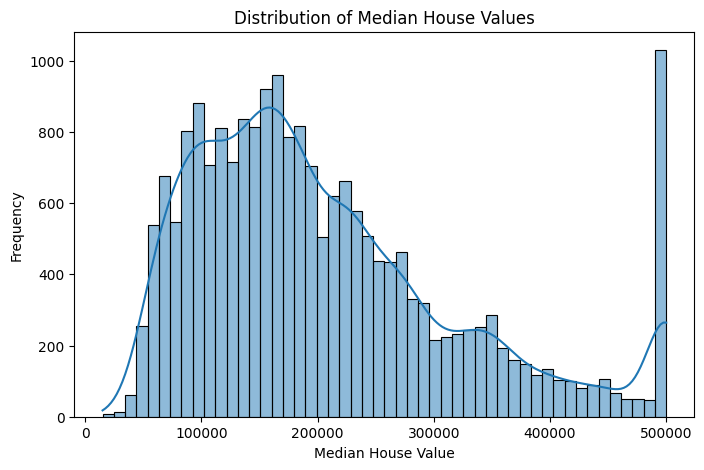

In [17]:
plt.figure(figsize=(8, 5))
sns.histplot(df['median_house_value'], bins=50, kde=True)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")

plt.show()

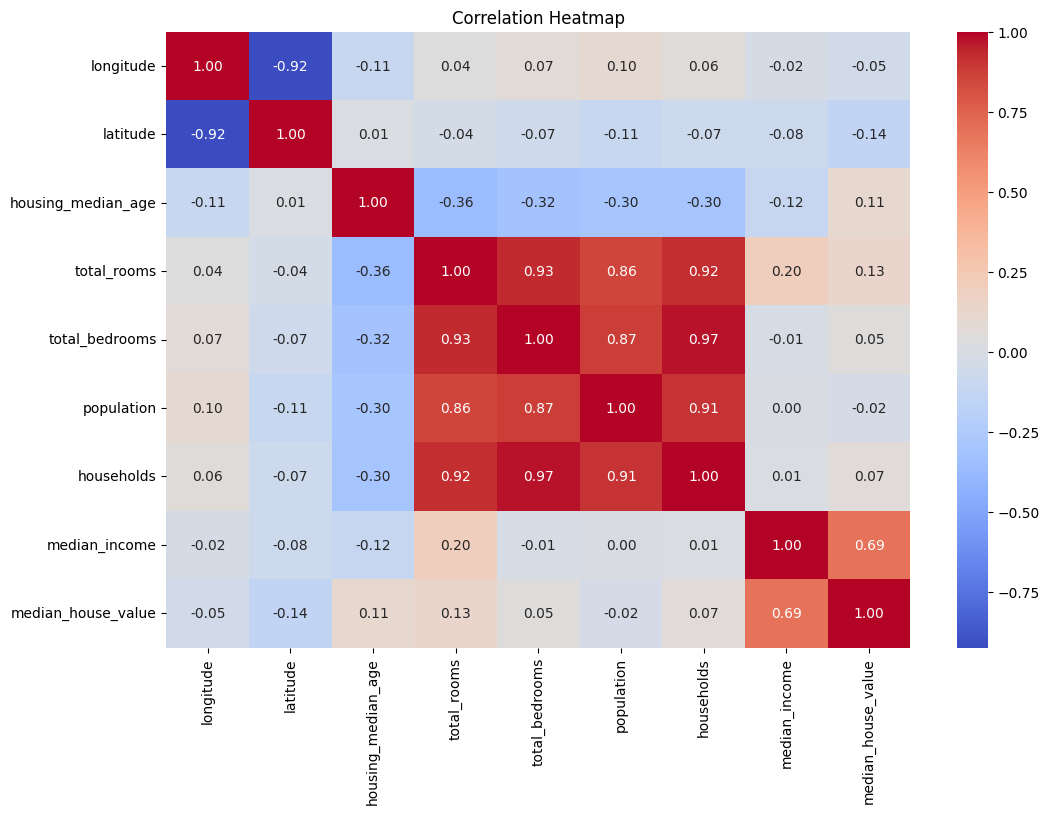

In [18]:
plt.figure(figsize=(12, 8))
numeric_df = df.select_dtypes(include=np.number)
correlation = numeric_df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

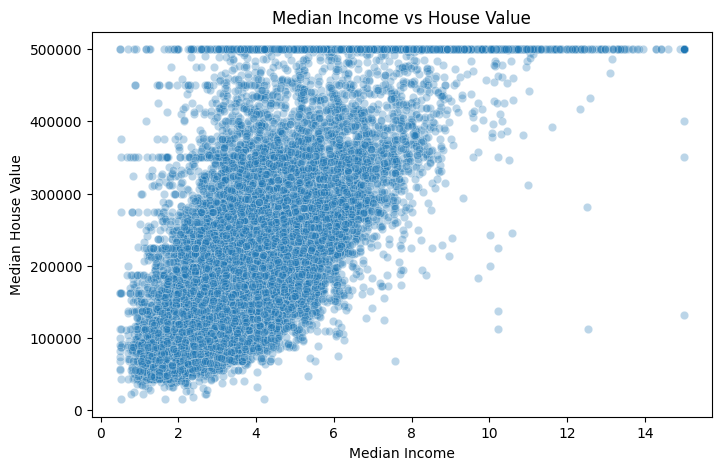

In [19]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x='median_income',
    y='median_house_value',
    data=df,
    alpha=0.3
)

plt.title("Median Income vs House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")

plt.show()

In [20]:
df['rooms_per_household'] = (
    df['total_rooms'] / df['households']
)

In [21]:
df['bedrooms_per_room'] = (
    df['total_bedrooms'] / df['total_rooms']
)

In [22]:
df['population_per_household'] = (
    df['population'] / df['households']
)

In [24]:
df[[
    'rooms_per_household',
    'bedrooms_per_room',
    'population_per_household'
]].head()

,rooms_per_household,bedrooms_per_room,population_per_household
0,6.984127,0.146591,2.555556
1,6.238137,0.155797,2.109842
2,8.288136,0.129516,2.802260
3,5.817352,0.184458,2.547945
4,6.281853,0.172096,2.181467


In [25]:
X = df.drop('median_house_value', axis=1)
y = df['median_house_value']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (20640, 12)
Target Shape: (20640,)


In [26]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household']
Categorical Features: ['ocean_proximity']


In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (16512, 12)
Testing Data: (4128, 12)


In [28]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [29]:
# Create OLS model
ols_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

# Train the model
ols_model.fit(X_train, y_train)

# Make predictions
ols_predictions = ols_model.predict(X_test)

print("OLS Model trained successfully!")

OLS Model trained successfully!


In [30]:
# Create Ridge model
ridge_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', Ridge())
])

# Train the model
ridge_model.fit(X_train, y_train)

# Make predictions
ridge_predictions = ridge_model.predict(X_test)

print("Ridge Model trained successfully!")

Ridge Model trained successfully!


In [31]:
# Create Lasso model
lasso_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', Lasso(max_iter=20000))
])

# Train the model
lasso_model.fit(X_train, y_train)

# Make predictions
lasso_predictions = lasso_model.predict(X_test)

print("Lasso Model trained successfully!")

Lasso Model trained successfully!


In [32]:
# Define Ridge parameter values
ridge_parameters = {
    'model__alpha': [0.01, 0.1, 1, 10, 100]
}

# Grid Search
ridge_grid = GridSearchCV(
    estimator=ridge_model,
    param_grid=ridge_parameters,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

# Fit Grid Search
ridge_grid.fit(X_train, y_train)

# Best parameters
print("Best Ridge Alpha:", ridge_grid.best_params_)
print("Best Ridge CV RMSE:", -ridge_grid.best_score_)

Best Ridge Alpha: {'model__alpha': 1}
Best Ridge CV RMSE: 67847.58552226017


In [33]:
# Define Lasso parameter values
lasso_parameters = {
    'model__alpha': [0.01, 0.1, 1, 10, 100]
}

# Grid Search
lasso_grid = GridSearchCV(
    estimator=lasso_model,
    param_grid=lasso_parameters,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

# Fit Grid Search
lasso_grid.fit(X_train, y_train)

# Best parameters
print("Best Lasso Alpha:", lasso_grid.best_params_)
print("Best Lasso CV RMSE:", -lasso_grid.best_score_)

Best Lasso Alpha: {'model__alpha': 1}
Best Lasso CV RMSE: 67848.71226030537


In [35]:
# Get the best Ridge and Lasso models
best_ridge_model = ridge_grid.best_estimator_
best_lasso_model = lasso_grid.best_estimator_

# Predictions using tuned models
ridge_predictions = best_ridge_model.predict(X_test)
lasso_predictions = best_lasso_model.predict(X_test)

In [36]:
def evaluate_model(y_true, y_pred):
    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    mae = mean_absolute_error(
        y_true, y_pred
    )

    r2 = r2_score(
        y_true, y_pred
    )

    return rmse, mae, r2

In [37]:
# Evaluate OLS
ols_rmse, ols_mae, ols_r2 = evaluate_model(
    y_test, ols_predictions
)

# Evaluate Ridge
ridge_rmse, ridge_mae, ridge_r2 = evaluate_model(
    y_test, ridge_predictions
)

# Evaluate Lasso
lasso_rmse, lasso_mae, lasso_r2 = evaluate_model(
    y_test, lasso_predictions
)

# Create comparison table
results = pd.DataFrame({
    'Model': ['OLS', 'Ridge', 'Lasso'],

    'RMSE': [
        ols_rmse,
        ridge_rmse,
        lasso_rmse
    ],

    'MAE': [
        ols_mae,
        ridge_mae,
        lasso_mae
    ],

    'R2 Score': [
        ols_r2,
        ridge_r2,
        lasso_r2
    ]
})

print(results)

   Model          RMSE           MAE  R2 Score
0    OLS  72668.538379  50888.660016  0.597018
1  Ridge  72677.921474  50897.578733  0.596914
2  Lasso  72668.968580  50889.734852  0.597013


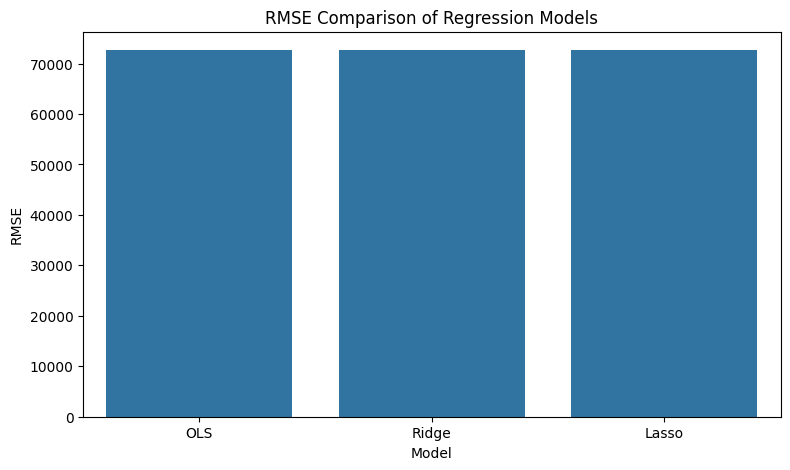

In [38]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results,
    x='Model',
    y='RMSE'
)

plt.title("RMSE Comparison of Regression Models")
plt.ylabel("RMSE")

plt.show()

In [39]:
# Select model with lowest RMSE
best_model_name = results.loc[
    results['RMSE'].idxmin(),
    'Model'
]

print("Best Model:", best_model_name)

# Select corresponding predictions
predictions = {
    'OLS': ols_predictions,
    'Ridge': ridge_predictions,
    'Lasso': lasso_predictions
}

best_predictions = predictions[best_model_name]

Best Model: OLS


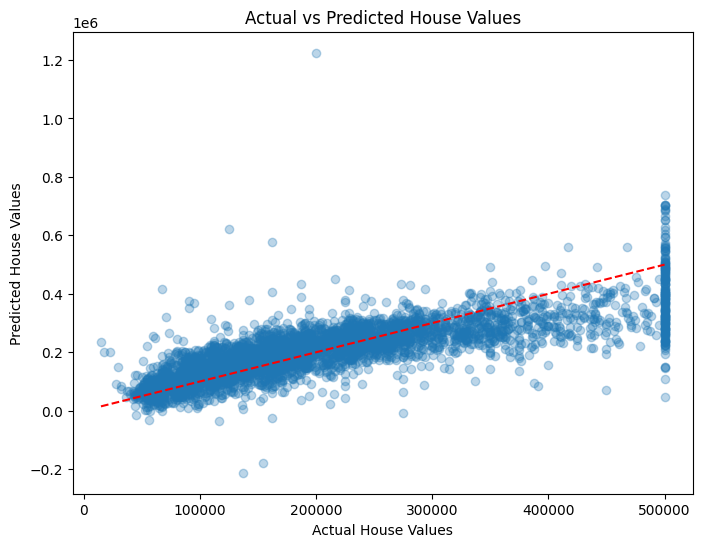

In [40]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.3
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Actual vs Predicted House Values")

plt.show()

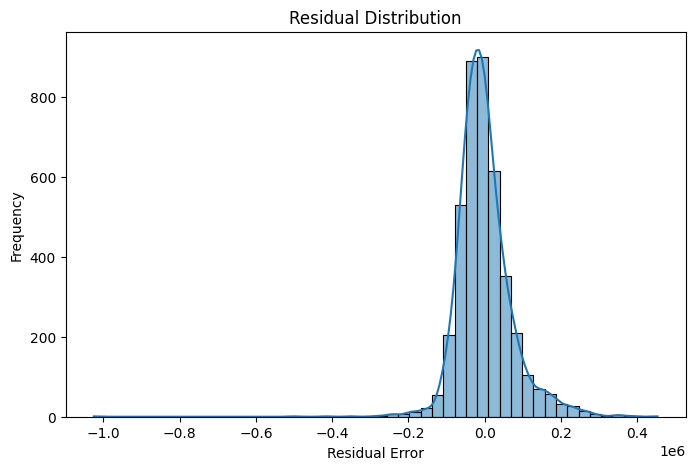

In [41]:
# Calculate residuals
residuals = y_test - best_predictions

plt.figure(figsize=(8, 5))

sns.histplot(
    residuals,
    kde=True,
    bins=50
)

plt.title("Residual Distribution")
plt.xlabel("Residual Error")
plt.ylabel("Frequency")

plt.show()

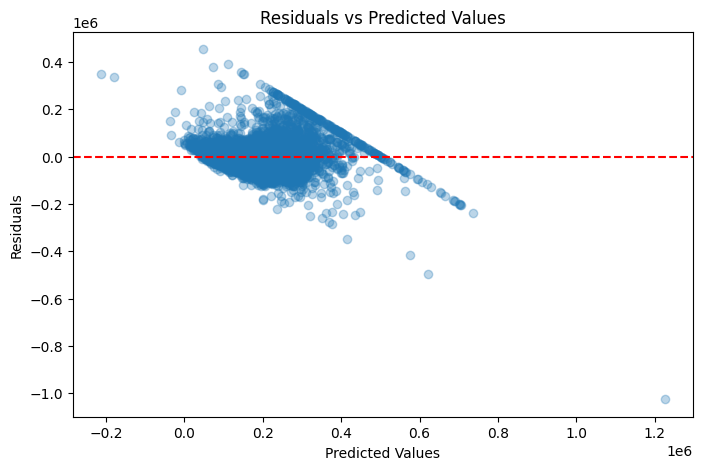

In [42]:
plt.figure(figsize=(8, 5))

plt.scatter(
    best_predictions,
    residuals,
    alpha=0.3
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")

plt.show()

In [44]:
# Display best model performance
best_result = results.loc[
    results['RMSE'].idxmin()
]

print("FINAL MODEL RESULTS")

print("Best Model:", best_result['Model'])

print("RMSE:", best_result['RMSE'])

print("MAE:", best_result['MAE'])

print("R2 Score:", best_result['R2 Score'])

FINAL MODEL RESULTS
Best Model: OLS
RMSE: 72668.53837868226
MAE: 50888.66001572008
R2 Score: 0.5970176824350761


In [45]:
import joblib

# Select best trained model
models = {
    'OLS': ols_model,
    'Ridge': best_ridge_model,
    'Lasso': best_lasso_model
}

best_model = models[best_model_name]

# Save model
joblib.dump(best_model, 'best_housing_model.pkl')
print("Best model saved successfully!")

Best model saved successfully!


In [46]:
import joblib
loaded_model = joblib.load('best_housing_model.pkl')

print("Model loaded successfully!")

Model loaded successfully!


In [47]:
# Select one test house
sample_house = X_test.iloc[[0]]

# Predict house value
predicted_price = loaded_model.predict(sample_house)

print("Predicted House Price:", predicted_price[0])
print("Actual House Price:", y_test.iloc[0])

Predicted House Price: 61463.74466640857
Actual House Price: 47700.0


In [48]:
# Create new house details

new_house = pd.DataFrame({
    'longitude': [-122.23],
    'latitude': [37.88],
    'housing_median_age': [20],
    'total_rooms': [2000],
    'total_bedrooms': [400],
    'population': [800],
    'households': [300],
    'median_income': [5.5],
    'ocean_proximity': ['NEAR BAY']
})

# Feature Engineering
new_house['rooms_per_household'] = (
    new_house['total_rooms'] / new_house['households']
)

new_house['bedrooms_per_room'] = (
    new_house['total_bedrooms'] / new_house['total_rooms']
)

new_house['population_per_household'] = (
    new_house['population'] / new_house['households']
)

# Predict house price
predicted_price = loaded_model.predict(new_house)

print("Predicted House Price: $", round(predicted_price[0], 2))

Predicted House Price: $ 286588.91


In [49]:
from google.colab import files
files.download('best_housing_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>